# PSI200 event-based dataset

PSI200 се записва на неравни интервали (~10 мин), останалите сензори - по-често.

Тук **не** разтягаме всичко до 1 час. Вместо това:

- **един ред = едно четене на PSI200** (това е target-ът)
- **всяка feature = средна стойност на сензора в интервала между предишното и текущото четене на PSI200**

За всяка feature пазим 4 колони: `_mean`, `_std`, `_n` (брой сурови проби), `_frozen` (мъртъв сензор).

`PSI80` е алтернативен target - записва се като колона, но **не** влиза в features.

**Ред на изпълнение:** конфигурация -> read_raw -> build -> run, после всичко останало.

In [33]:
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

ENGINE = create_engine(
    'mssql+pyodbc:///?odbc_connect='
    'DRIVER={ODBC Driver 17 for SQL Server};SERVER=10.20.2.10;'
    'DATABASE=pulse;UID=Pulse_RO;PWD=PD@T@r3@der'
)

# feature -> { MillName: TagID }
SQL_TAGS = {
    'Ore':        {'Mill06': '500',  'Mill07': '455',  'Mill08': '467'},
    'WaterMill':  {'Mill06': '1219', 'Mill07': '461',  'Mill08': '474'},
    'WaterZumpf': {'Mill06': '1220', 'Mill07': '462',  'Mill08': '475'},
    'Power':      {'Mill06': '502',  'Mill07': '460',  'Mill08': '471'},
    'ZumpfLevel': {'Mill06': '501',  'Mill07': '458',  'Mill08': '470'},
    'PressureHC': {'Mill06': '1217', 'Mill07': '459',  'Mill08': '472'},
    'DensityHC':  {'Mill06': '1216', 'Mill07': '457',  'Mill08': '469'},
    'FE':         {'Mill06': '1762', 'Mill07': '1762', 'Mill08': '1762'},
    'PulpHC':     {'Mill06': '2777', 'Mill07': '2837', 'Mill08': '1833'},
    'PumpRPM':    {'Mill06': '2796', 'Mill07': '2856', 'Mill08': '1800'},
    'MotorAmp':   {'Mill06': '2770', 'Mill07': '2830', 'Mill08': '1805'},
    'PSI80':      {'Mill06': '5329', 'Mill07': '5331', 'Mill08': '5332'},
    'PSI200':     {'Mill06': '5328', 'Mill07': '5330', 'Mill08': '5333'},
}

TABLE_NAMES = ['LoggerValues'] + [
    f'LoggerValues_Archive_{m}{y}'
    for y in (2026, 2025)
    for m in ('Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec')
    if not (y == 2026 and m in ('Oct', 'Nov', 'Dec'))
]

TARGET, ALT_TARGET = 'PSI200', 'PSI80'
FEATURES = [f for f in SQL_TAGS if f not in (TARGET, ALT_TARGET)]
print(f'{len(FEATURES)} features:', FEATURES)

11 features: ['Ore', 'WaterMill', 'WaterZumpf', 'Power', 'ZumpfLevel', 'PressureHC', 'DensityHC', 'FE', 'PulpHC', 'PumpRPM', 'MotorAmp']


In [34]:
def read_raw(start=None, end=None):
    """Сурови данни: {feature: {mill: Series}}. Без resample, без ffill."""
    tag_map = {}
    for feat, mills in SQL_TAGS.items():
        for mill, tag in mills.items():
            tag_map.setdefault(tag, []).append((feat, mill))

    tags = ','.join(tag_map)
    frames = []
    for tbl in TABLE_NAMES:
        q = f'SELECT IndexTime, LoggerTagID, Value FROM {tbl} WHERE LoggerTagID IN ({tags})'
        if start:
            q += f' AND IndexTime >= {start!r}'
        if end:
            q += f' AND IndexTime < {end!r}'
        d = pd.read_sql_query(q, ENGINE)
        print(f'{tbl:<32} {len(d):>8}')
        if not d.empty:
            frames.append(d)

    raw = pd.concat(frames, ignore_index=True)
    raw['LoggerTagID'] = raw['LoggerTagID'].astype(str)
    raw['IndexTime'] = pd.to_datetime(raw['IndexTime'])
    # dedup по (време, таг) - иначе при еднакъв IndexTime губим мелници
    raw = raw.drop_duplicates(['IndexTime', 'LoggerTagID'], keep='last').sort_values('IndexTime')

    out = {}
    for tag, targets in tag_map.items():
        s = raw.loc[raw['LoggerTagID'] == tag].set_index('IndexTime')['Value'].sort_index()
        s = s[~s.index.duplicated(keep='last')]
        for feat, mill in targets:
            out.setdefault(feat, {})[mill] = s
    return out

In [35]:
def build(raw, mill, lag=0, max_gap=60):
    """1 ред на PSI200 четене; features = mean/std/n в интервала до предишното четене."""
    psi = raw[TARGET][mill].dropna()
    edges = (psi.index - pd.Timedelta(minutes=lag)).values
    n = len(psi) - 1

    out = pd.DataFrame(index=psi.index[1:])
    out.index.name = 'TimeStamp'
    out[TARGET] = psi.values[1:]
    out['dt_sec'] = np.diff(psi.index.values) / np.timedelta64(1, 's')

    # алтернативен target (не е feature)
    out[ALT_TARGET] = raw[ALT_TARGET][mill].dropna().reindex(
        out.index, method='nearest', tolerance='15min')

    for feat in FEATURES:
        s = raw.get(feat, {}).get(mill)
        if s is None or s.dropna().empty:
            out[f'{feat}_mean'] = np.nan
            out[f'{feat}_std'] = np.nan
            out[f'{feat}_n'] = 0
            out[f'{feat}_frozen'] = True
            continue

        s = s.dropna()
        # в кой прозорец попада всяка сурова стойност
        pos = np.searchsorted(edges, s.index.values, side='left') - 1
        ok = (pos >= 0) & (pos < n)
        g = pd.DataFrame({'pos': pos[ok], 'v': s.values[ok]}).groupby('pos')['v']
        st = pd.DataFrame({'mean': g.mean(), 'std': g.std(), 'n': g.count()}).reindex(range(n))

        out[f'{feat}_mean'] = st['mean'].values
        out[f'{feat}_std'] = st['std'].values
        out[f'{feat}_n'] = st['n'].fillna(0).astype(int).values
        # замръзнал: >1 проба, но всички еднакви
        out[f'{feat}_frozen'] = ((st['n'] > 1) & (st['std'].fillna(0) == 0)).values

    out['n_features_ok'] = out[[f'{f}_mean' for f in FEATURES]].notna().sum(axis=1)
    if max_gap:
        out = out[out['dt_sec'] <= max_gap * 60]
    return out

In [36]:
def clean(df, min_coverage=0.5):
    """Запълва NaN в features. Връща (df, keep, dropped).

    - features с покритие < min_coverage се изхвърлят (няма смисъл да се запълват)
    - _std при n == 1 -> 0 (има проба, но няма вариация)
    - празен прозорец (n == 0) -> ffill, после bfill за началото
    """
    coverage = {f: (df[f'{f}_n'] > 0).mean() for f in FEATURES}
    keep = [f for f in FEATURES if coverage[f] >= min_coverage]
    dropped = [f for f in FEATURES if f not in keep]

    out = df.copy()
    for f in keep:
        n = out[f'{f}_n']
        out[f'{f}_std'] = out[f'{f}_std'].mask(n == 1, 0.0).ffill().bfill()
        out[f'{f}_mean'] = out[f'{f}_mean'].ffill().bfill()

    # колко features са били запълнени в реда (не са имали нито една проба)
    out['n_ffilled'] = sum((out[f'{f}_n'] == 0).astype(int) for f in keep)

    out = out.drop(columns=[f'{f}_{s}' for f in dropped for s in ('mean', 'std', 'n', 'frozen')],
                   errors='ignore')
    out = out.drop(columns=['n_features_ok'], errors='ignore')
    return out, keep, dropped

In [37]:
# период на селекция (край преди аварията на PSI200: Oct 4-21 сензорът е мъртъв)
START, END = '2026-07-01', '2026-09-30'
raw = read_raw(START, END)
df, keep, dropped = clean(build(raw, 'Mill06'))

print('Изхвърлени (покритие < 50%):', dropped)
print('Останали features:', len(keep), '->', keep)
print()

feat_cols = [f'{f}_{s}' for f in keep for s in ('mean', 'std', 'n', 'frozen')]
counts = df[feat_cols].notna().sum()
print('Редове:', len(df))
print('Non-null по feature колони (уникални):', counts.unique())
print('Всички равни и пълни:', counts.nunique() == 1 and counts.iloc[0] == len(df))
print()

# PSI80 е алтернативен target и НЕ се запълва. Ако го ползваш като target:
# df = df[df['PSI80'].notna()].copy()

FEATURES = keep   # за да работят клетките по-долу
df.info()

LoggerValues                       236212
LoggerValues_Archive_Jan2026            0
LoggerValues_Archive_Feb2026            0
LoggerValues_Archive_Mar2026            0
LoggerValues_Archive_Apr2026            0
LoggerValues_Archive_May2026            0
LoggerValues_Archive_Jun2026            0
LoggerValues_Archive_Jul2026      3646930
LoggerValues_Archive_Aug2026      3511242
LoggerValues_Archive_Sep2026      3079586
LoggerValues_Archive_Jan2025            0
LoggerValues_Archive_Feb2025            0
LoggerValues_Archive_Mar2025            0
LoggerValues_Archive_Apr2025            0
LoggerValues_Archive_May2025            0
LoggerValues_Archive_Jun2025            0
LoggerValues_Archive_Jul2025            0
LoggerValues_Archive_Aug2025            0
LoggerValues_Archive_Sep2025            0
LoggerValues_Archive_Oct2025            0
LoggerValues_Archive_Nov2025            0
LoggerValues_Archive_Dec2025            0
Изхвърлени (покритие < 50%): ['FE']
Останали features: 10 -> ['Ore', 'WaterM

In [38]:
df.describe()

,PSI200,dt_sec,PSI80,Ore_mean,Ore_std,Ore_n,WaterMill_mean,WaterMill_std,WaterMill_n,WaterZumpf_mean,WaterZumpf_std,WaterZumpf_n,Power_mean,Power_std,Power_n,ZumpfLevel_mean,ZumpfLevel_std,ZumpfLevel_n,PressureHC_mean,PressureHC_std,PressureHC_n,DensityHC_mean,DensityHC_std,DensityHC_n,PulpHC_mean,PulpHC_std,PulpHC_n,PumpRPM_mean,PumpRPM_std,PumpRPM_n,MotorAmp_mean,MotorAmp_std,MotorAmp_n,n_ffilled
count,10966.000000,10966.000000,10365.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000,10966.000000
mean,25.488601,698.353819,50.791877,172.727804,1.279496,7.316250,10.464696,0.131012,55.272479,119.412591,6.095224,8.244483,1922.313511,54.639965,68.075324,1608.895167,31.246226,52.469998,0.413633,0.003355,47.041857,1649.966324,3.163452,18.856465,326.372996,2.971107,25.792632,654.841881,1.208907,5.679008,203.566407,5.898875,62.329746,0.532738
std,139.028574,455.075256,3.196594,14.965220,4.866552,7.023414,3.909527,0.270158,37.688022,46.386825,6.590829,8.967274,32.818067,12.760687,44.285959,54.445994,25.138837,32.309230,0.026501,0.007378,32.312084,38.116518,6.140573,12.698647,45.150416,4.402481,18.069442,15.315249,6.390252,9.869167,3.443536,1.083842,40.676266,0.733396
min,1.000000,12.323000,36.300000,9.477500,0.000000,0.000000,0.017000,0.009170,0.000000,0.000000,0.000000,0.000000,1643.916667,25.012299,0.000000,271.033250,1.478659,0.000000,0.006333,0.000577,0.000000,1200.240000,0.000000,0.000000,10.056700,0.000000,0.000000,471.438000,0.000000,0.000000,181.897417,2.832424,0.000000,0.000000
25%,20.500000,479.325500,49.100000,170.093488,0.749283,3.000000,9.316432,0.036987,36.000000,89.821352,0.787010,1.000000,1896.893743,50.712702,47.000000,1584.312804,9.356834,34.000000,0.409779,0.002225,30.000000,1636.352308,1.532160,11.000000,295.506468,1.688726,16.000000,649.451750,0.656508,0.000000,200.739793,5.482756,42.000000,0.000000
50%,22.200000,484.575000,50.500000,175.710417,0.872181,6.000000,11.936267,0.079783,41.000000,106.528567,4.336307,6.000000,1921.874212,54.260919,47.000000,1605.642563,25.874864,42.000000,0.418016,0.002642,35.000000,1653.194968,2.522619,15.000000,336.562601,2.498681,20.000000,656.346000,0.847821,2.000000,203.690476,5.868379,44.000000,0.000000
75%,24.600000,954.393750,52.000000,180.546875,1.017517,9.000000,13.029542,0.190128,67.000000,159.743000,9.905481,12.000000,1949.246749,57.929385,92.000000,1634.278246,51.290987,60.000000,0.424412,0.003258,58.000000,1670.446426,3.929684,22.000000,357.688746,3.496631,30.000000,663.754773,1.162910,6.000000,206.501616,6.260500,83.000000,1.000000
max,6553.200000,3599.833000,205.600000,218.765441,130.866356,276.000000,16.517341,16.770453,331.000000,274.493167,109.803773,84.000000,2014.141613,807.432701,354.000000,1950.692632,692.517285,303.000000,0.483950,0.277583,286.000000,1770.117143,433.634829,156.000000,463.278667,141.148677,199.000000,791.986800,275.150805,207.000000,214.697333,57.293242,333.000000,10.000000


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10966 entries, 2026-07-01 00:16:19.490000 to 2026-09-29 23:58:05.837000
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PSI200             10966 non-null  float64
 1   dt_sec             10966 non-null  float64
 2   PSI80              10365 non-null  float64
 3   Ore_mean           10966 non-null  float64
 4   Ore_std            10966 non-null  float64
 5   Ore_n              10966 non-null  int64  
 6   Ore_frozen         10966 non-null  bool   
 7   WaterMill_mean     10966 non-null  float64
 8   WaterMill_std      10966 non-null  float64
 9   WaterMill_n        10966 non-null  int64  
 10  WaterMill_frozen   10966 non-null  bool   
 11  WaterZumpf_mean    10966 non-null  float64
 12  WaterZumpf_std     10966 non-null  float64
 13  WaterZumpf_n       10966 non-null  int64  
 14  WaterZumpf_frozen  10966 non-null  bool   
 15  Power_mean         10

C:\Users\s.lyubenov\AppData\Local\Temp\ipykernel_7688\4181230360.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


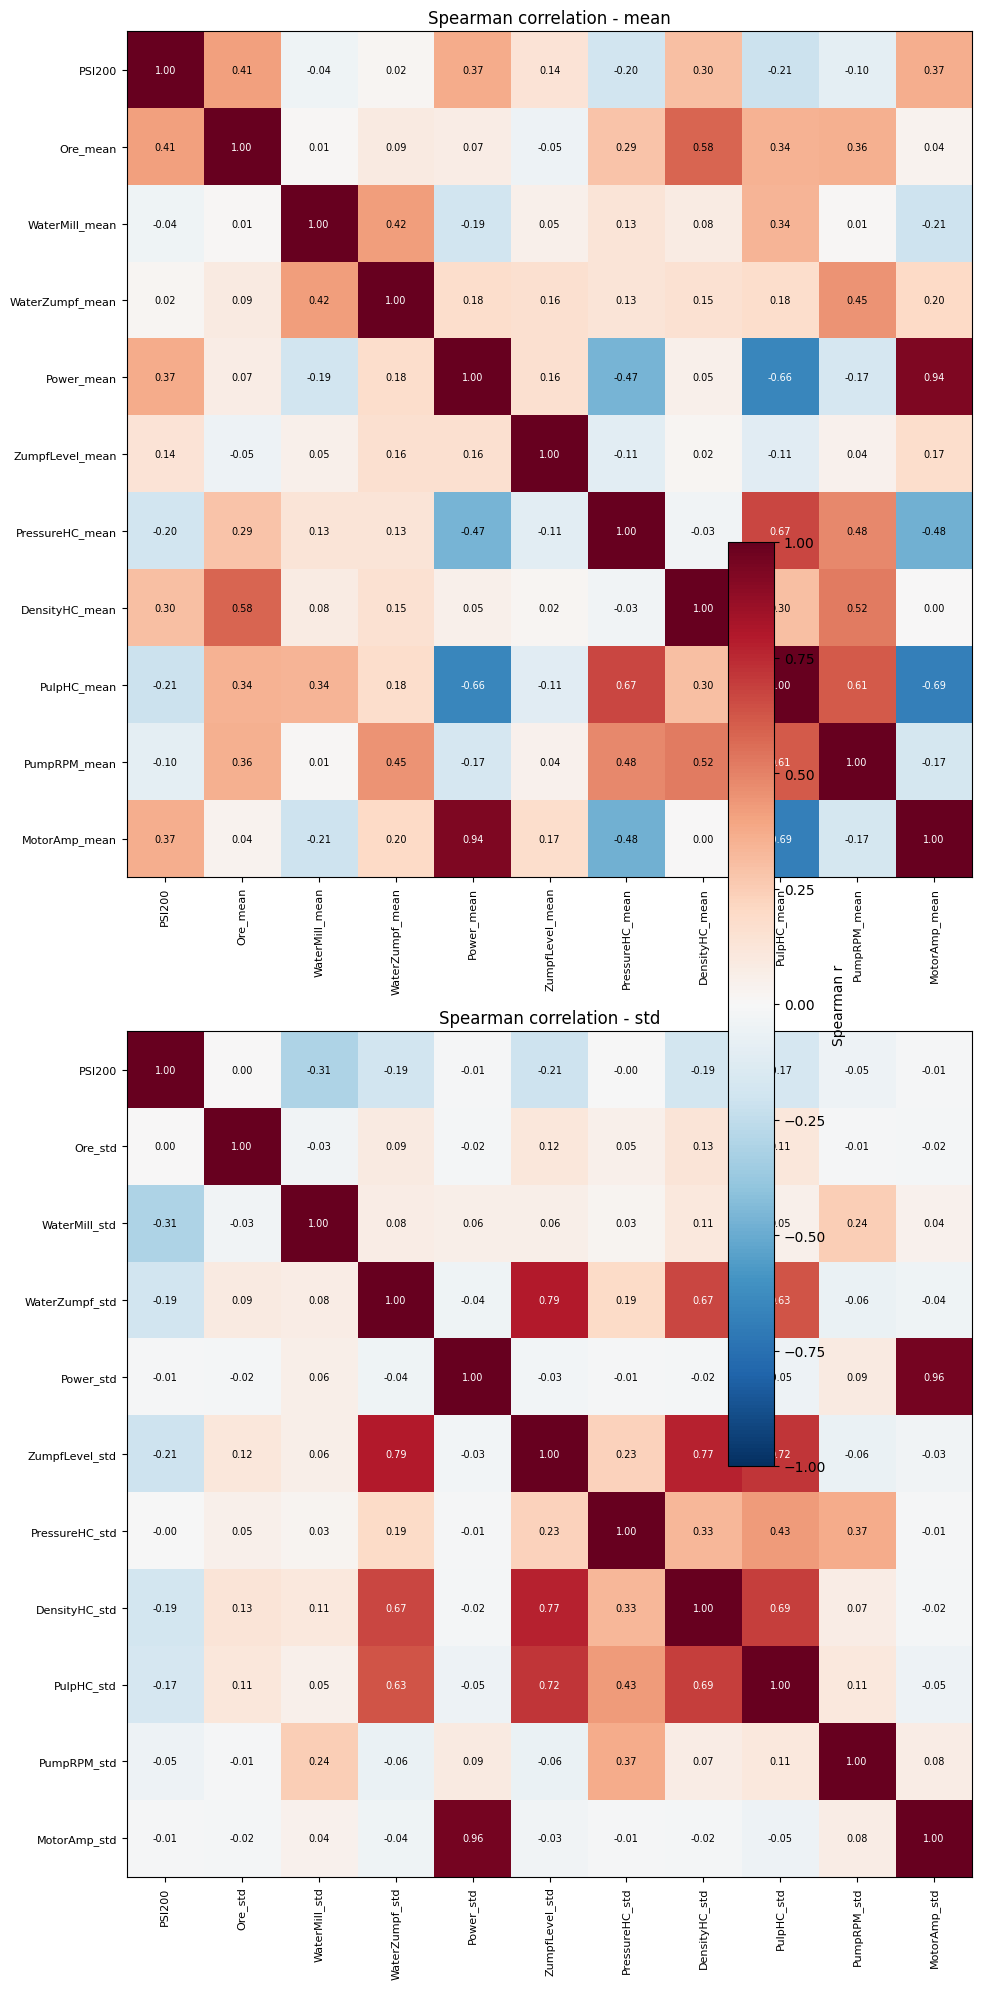

In [40]:
import matplotlib.pyplot as plt


def corr_block(kind):
    cols = [TARGET] + [f'{f}_{kind}' for f in FEATURES]
    return cols, df[cols].corr(method='spearman')


def draw(ax, cols, corr, title):
    im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels(cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = corr.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(v) > 0.6 else 'black')
    ax.set_title(title)
    return im


fig, axes = plt.subplots(2, 1, figsize=(12, 20))

for ax, kind in zip(axes, ('mean', 'std')):
    cols, corr = corr_block(kind)
    im = draw(ax, cols, corr, f'Spearman correlation - {kind}')

fig.colorbar(im, ax=axes, shrink=.6, label='Spearman r')
plt.tight_layout()
plt.show()

In [41]:
# 1. Features / target + хронологичен train/test split
# само _mean частта - _std се изключва
DROP_FEATURES = ['ZumpfLevel', 'Power']
FEAT_COLS = [f'{f}_mean' for f in FEATURES if f not in DROP_FEATURES]

X = df[FEAT_COLS].astype(float)
y = df[TARGET].astype(float)

# филтри преди split
mask_target = y.between(15, 30)          # PSI200 извън [15, 30]
mask_ore = X['Ore_mean'] >= 120          # Ore < 120
mask = mask_target & mask_ore

print(f'Изхвърлени по target (PSI200 < 15 или > 30): {int((~mask_target).sum())} от {len(y)}')
print(f'Изхвърлени по Ore_mean < 120:               {int((~mask_ore).sum())} от {len(y)}')
print(f'Остават след филтрите:                      {int(mask.sum())} реда')
X, y = X[mask], y[mask]

# ВАЖНО: данните са времеви ред -> split по време, НЕ random.
# Иначе моделът "вижда" бъдещето и резултатите са фалшиво добри.
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print()
print(f'X: {X.shape}   ({len(FEAT_COLS)} features, само _mean)')
print(f'train: {len(X_train):>6} реда   {X_train.index.min()}  ..  {X_train.index.max()}')
print(f'test : {len(X_test):>6} реда   {X_test.index.min()}  ..  {X_test.index.max()}')
print()
print(f'target {TARGET}: mean={y.mean():.3f}  std={y.std():.3f}  '
      f'min={y.min():.3f}  max={y.max():.3f}')
print(f'NaN в X: {int(X.isna().sum().sum())}   NaN в y: {int(y.isna().sum())}')
print()
print('Features:', FEAT_COLS)

Изхвърлени по target (PSI200 < 15 или > 30): 161 от 10966
Изхвърлени по Ore_mean < 120:               290 от 10966
Остават след филтрите:                      10586 реда

X: (10586, 8)   (8 features, само _mean)
train:   8468 реда   2026-07-01 00:16:19.490000  ..  2026-09-07 20:11:16.917000
test :   2118 реда   2026-09-07 20:43:21.927000  ..  2026-09-29 23:58:05.837000

target PSI200: mean=22.672  std=2.763  min=15.000  max=30.000
NaN в X: 0   NaN в y: 0

Features: ['Ore_mean', 'WaterMill_mean', 'WaterZumpf_mean', 'PressureHC_mean', 'DensityHC_mean', 'PulpHC_mean', 'PumpRPM_mean', 'MotorAmp_mean']


In [42]:
# 2. Preprocessing pipeline
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# XGBoost е дървовиден модел -> не се нуждае от StandardScaler.
# Оставяме само imputer, за да е явно и да работи и с NaN.
num_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
])

print(num_pipeline)

Pipeline(steps=[('impute', SimpleImputer(strategy='median'))])


In [43]:
# 3. Helper за оценка на модел
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluate(name, model):
    """Fit-ва модела и връща метриките за train и test."""
    model.fit(X_train, y_train)
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)

    row = {
        'model': name,
        'rmse_train': mean_squared_error(y_train, pred_tr) ** 0.5,
        'rmse_test': mean_squared_error(y_test, pred_te) ** 0.5,
        'mae_test': mean_absolute_error(y_test, pred_te),
        'r2_test': r2_score(y_test, pred_te),
    }
    print(f'{name:<20} RMSE train={row["rmse_train"]:8.3f}   '
          f'test={row["rmse_test"]:8.3f}   '
          f'MAE={row["mae_test"]:7.3f}   R2={row["r2_test"]:6.3f}')
    return row


print('Готово.')

Готово.


In [44]:
# 4. XGBoost - обучение
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

xgb_reg = make_pipeline(num_pipeline, XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    objective='reg:squarederror',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
))

xgb_result = evaluate('XGBoost', xgb_reg)

XGBoost              RMSE train=   0.714   test=   2.918   MAE=  2.500   R2=-0.181


In [45]:
# 5. Cross-validation (XGBoost)
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

# KFold - както в книгата, но разбърква времето -> оптимистична оценка
kf = -cross_val_score(xgb_reg, X, y, scoring='neg_root_mean_squared_error',
                      cv=KFold(5, shuffle=True, random_state=42), n_jobs=-1)
# TimeSeriesSplit - train винаги е ПРЕДИ validation -> честна оценка
ts = -cross_val_score(xgb_reg, X, y, scoring='neg_root_mean_squared_error',
                      cv=TimeSeriesSplit(n_splits=5), n_jobs=-1)

print(f'KFold        RMSE: {kf.mean():8.3f} ± {kf.std():5.3f}   {np.round(kf, 2)}')
print(f'TimeSeries   RMSE: {ts.mean():8.3f} ± {ts.std():5.3f}   {np.round(ts, 2)}')
print()
print('KFold е по-нисък, защото "вижда" бъдещи редове. Гледай TimeSeries реда.')

KFold        RMSE:    1.271 ± 0.013   [1.27 1.26 1.3  1.26 1.26]
TimeSeries   RMSE:    2.870 ± 0.665   [1.81 3.65 2.44 3.37 3.07]

KFold е по-нисък, защото "вижда" бъдещи редове. Гледай TimeSeries реда.


Feature importance:
Ore_mean           0.2435
WaterZumpf_mean    0.1286
WaterMill_mean     0.1285
MotorAmp_mean      0.1253
DensityHC_mean     0.1236
PulpHC_mean        0.0923
PressureHC_mean    0.0836
PumpRPM_mean       0.0746

Сума на top 5: 0.750   брой features с importance < 0.01: 0


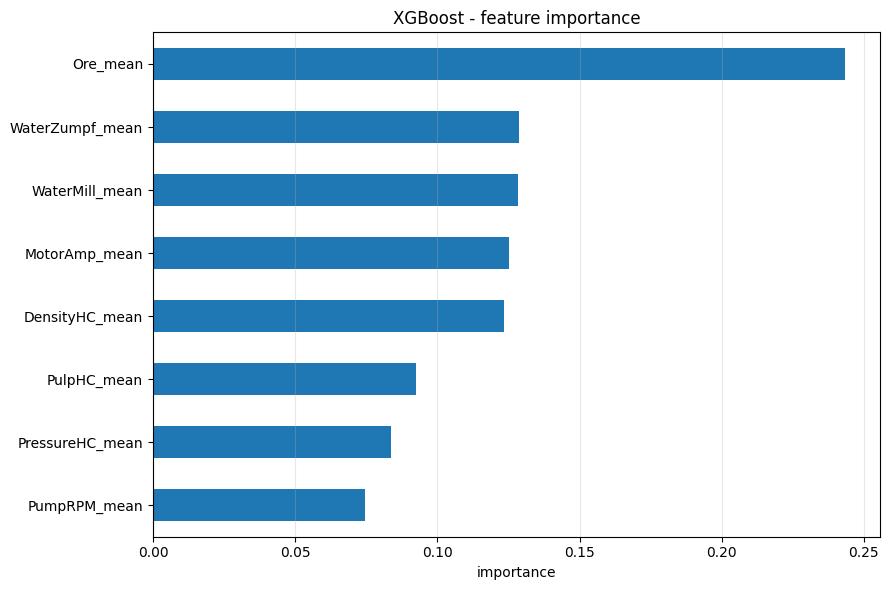

In [46]:
# 6. Feature importance (XGBoost)
import matplotlib.pyplot as plt

xgb = xgb_reg.named_steps['xgbregressor']
imp = pd.Series(xgb.feature_importances_, index=FEAT_COLS).sort_values(ascending=False)

print('Feature importance:')
print(imp.round(4).to_string())
print()
print(f'Сума на top 5: {imp.head(5).sum():.3f}   '
      f'брой features с importance < 0.01: {(imp < 0.01).sum()}')

ax = imp[::-1].plot.barh(figsize=(9, 6))
ax.set_xlabel('importance')
ax.set_title('XGBoost - feature importance')
ax.grid(axis='x', alpha=.3)
plt.tight_layout()
plt.show()

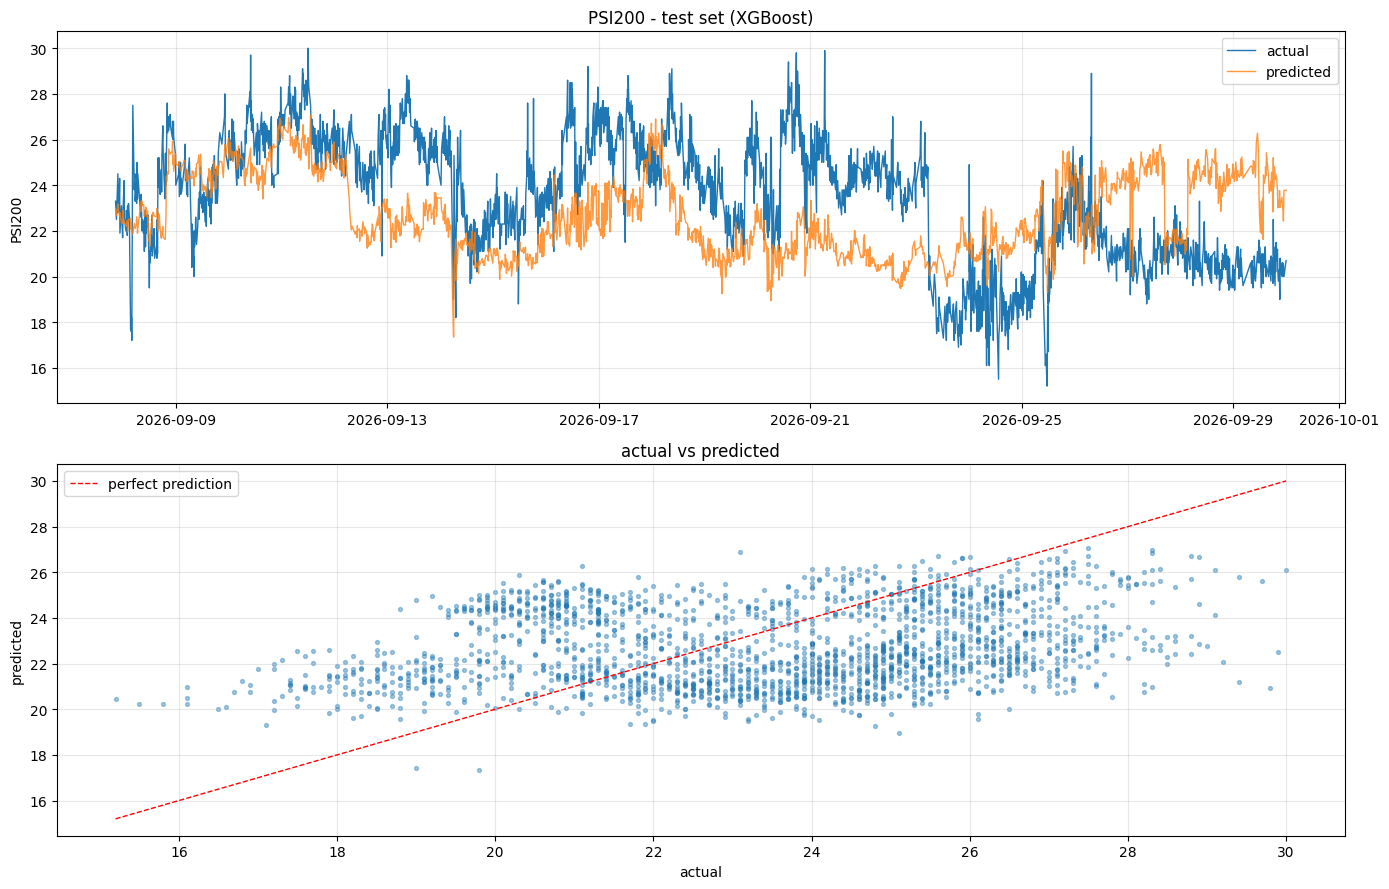

In [47]:
# 7. Predictions vs actual (test set, XGBoost)
pred_test = xgb_reg.predict(X_test)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(y_test.index, y_test.values, label='actual', lw=1)
axes[0].plot(y_test.index, pred_test, label='predicted', lw=1, alpha=.8)
axes[0].set_title(f'{TARGET} - test set (XGBoost)')
axes[0].set_ylabel(TARGET)
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].scatter(y_test, pred_test, s=8, alpha=.4)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[1].plot(lims, lims, 'r--', lw=1, label='perfect prediction')
axes[1].set_xlabel('actual')
axes[1].set_ylabel('predicted')
axes[1].set_title('actual vs predicted')
axes[1].legend()
axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

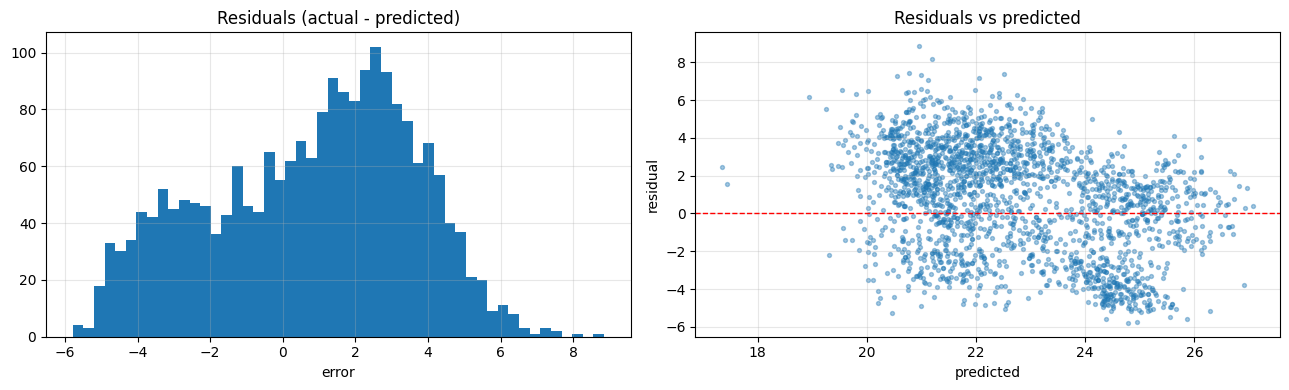

count    2118.000
mean        0.761
std         2.818
min        -5.786
25%        -1.371
50%         1.214
75%         2.901
max         8.849

Bias (mean residual): 0.761
RMSE: 2.918


In [48]:
# 8. Residuals (test set, XGBoost)
pred_test = xgb_reg.predict(X_test)
resid = y_test - pred_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(resid, bins=50)
axes[0].set_title('Residuals (actual - predicted)')
axes[0].set_xlabel('error')
axes[0].grid(alpha=.3)

axes[1].scatter(pred_test, resid, s=8, alpha=.4)
axes[1].axhline(0, color='r', ls='--', lw=1)
axes[1].set_xlabel('predicted')
axes[1].set_ylabel('residual')
axes[1].set_title('Residuals vs predicted')
axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

print(resid.describe().round(3).to_string())
print()
print(f'Bias (mean residual): {resid.mean():.3f}')
print(f'RMSE: {(resid ** 2).mean() ** 0.5:.3f}')